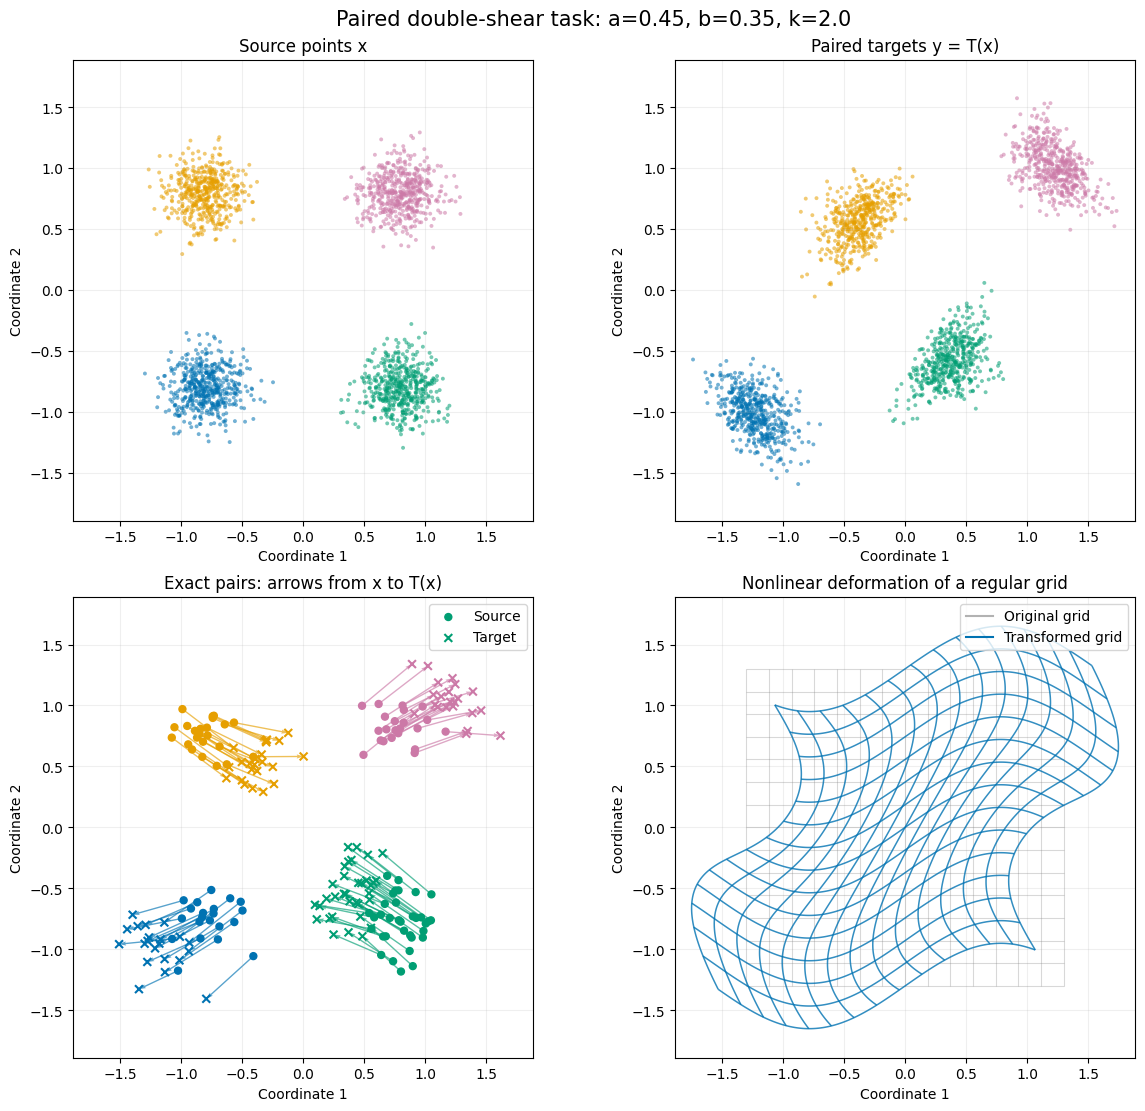

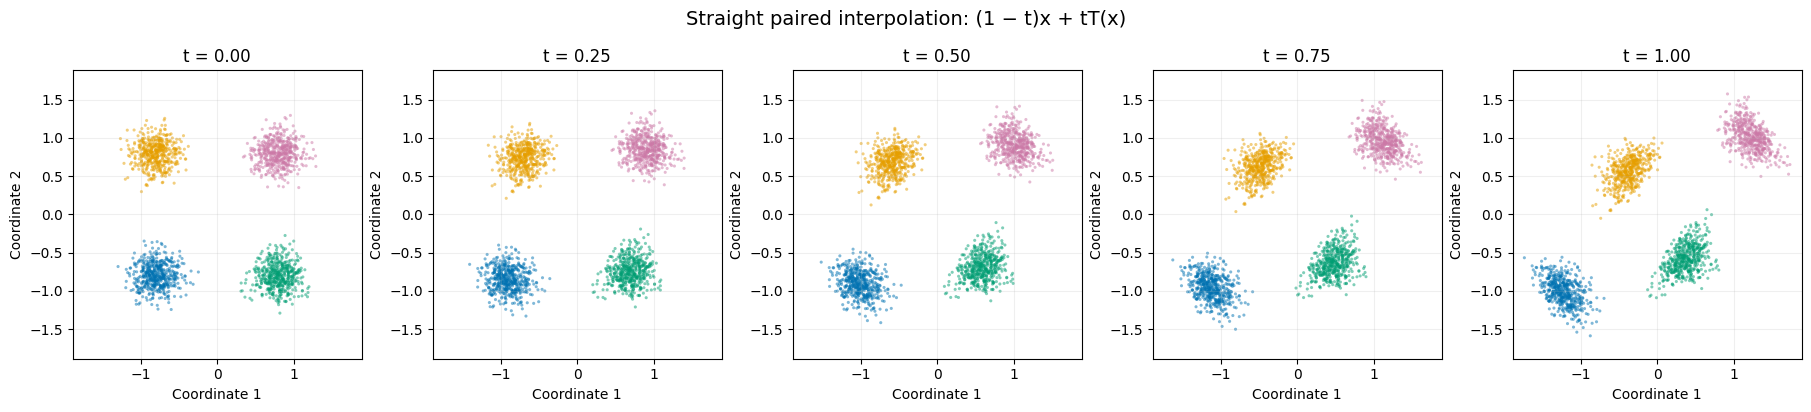

Number of pairs: 2,000
Mean displacement: 0.4871
Maximum displacement: 0.5695
Maximum inverse reconstruction error: 3.14e-16


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
SEED = 42
N_POINTS = 2000
CLUSTER_STD = 0.16

A = 0.45
B = 0.35
K = 2.0

rng = np.random.default_rng(SEED)

# ------------------------------------------------------------
# Ground-truth transformation and its inverse
# ------------------------------------------------------------
def transform(x, a=A, b=B, k=K):
    """x: array of shape [..., 2]."""
    x1, x2 = x[..., 0], x[..., 1]
    u = x1 + a * np.sin(k * x2)
    v = x2 + b * np.sin(k * u)
    return np.stack([u, v], axis=-1)


def inverse_transform(y, a=A, b=B, k=K):
    """y: array of shape [..., 2]."""
    u, v = y[..., 0], y[..., 1]
    x2 = v - b * np.sin(k * u)
    x1 = u - a * np.sin(k * x2)
    return np.stack([x1, x2], axis=-1)


def interpolate(x, t):
    """Straight interpolation between each source and its target."""
    return (1.0 - t) * x + t * transform(x)


# ------------------------------------------------------------
# Generate paired data
# ------------------------------------------------------------
centers = np.array([
    [-0.8, -0.8],
    [-0.8,  0.8],
    [ 0.8, -0.8],
    [ 0.8,  0.8],
])

cluster_ids = rng.integers(0, len(centers), size=N_POINTS)
x = centers[cluster_ids] + CLUSTER_STD * rng.normal(
    size=(N_POINTS, 2)
)
y = transform(x)

palette = np.array([
    "#0072B2",
    "#E69F00",
    "#009E73",
    "#CC79A7",
])
point_colors = palette[cluster_ids]

# Numerical consistency check.
reconstructed_x = inverse_transform(y)
inverse_error = np.linalg.norm(reconstructed_x - x, axis=1)
assert np.allclose(reconstructed_x, x, atol=1e-10)

# ------------------------------------------------------------
# Shared plot formatting
# ------------------------------------------------------------
extent = np.max(np.abs(np.concatenate([x, y], axis=0))) + 0.15

def format_ax(ax, title, limit=extent):
    ax.set_title(title)
    ax.set_xlabel("Coordinate 1")
    ax.set_ylabel("Coordinate 2")
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

# ------------------------------------------------------------
# Figure 1: source, target, pair correspondence, grid warp
# ------------------------------------------------------------
fig, axes = plt.subplots(
    2, 2, figsize=(12, 11), constrained_layout=True
)

axes[0, 0].scatter(
    x[:, 0], x[:, 1],
    c=point_colors, s=8, alpha=0.55, linewidths=0,
)
format_ax(axes[0, 0], "Source points x")

axes[0, 1].scatter(
    y[:, 0], y[:, 1],
    c=point_colors, s=8, alpha=0.55, linewidths=0,
)
format_ax(axes[0, 1], "Paired targets y = T(x)")

# Draw only a subset of arrows to keep correspondence readable.
selected = rng.choice(N_POINTS, size=100, replace=False)
xs, ys = x[selected], y[selected]

axes[1, 0].scatter(
    xs[:, 0], xs[:, 1],
    c=point_colors[selected], s=25, marker="o",
    label="Source", zorder=3,
)
axes[1, 0].scatter(
    ys[:, 0], ys[:, 1],
    c=point_colors[selected], s=32, marker="x",
    label="Target", zorder=3,
)
axes[1, 0].quiver(
    xs[:, 0], xs[:, 1],
    ys[:, 0] - xs[:, 0],
    ys[:, 1] - xs[:, 1],
    color=point_colors[selected],
    angles="xy", scale_units="xy", scale=1,
    width=0.003, alpha=0.65,
)
axes[1, 0].legend()
format_ax(axes[1, 0], "Exact pairs: arrows from x to T(x)")

# Regular grid and its transformed image.
grid_positions = np.linspace(-1.3, 1.3, 15)
line_coordinate = np.linspace(-1.3, 1.3, 250)

grid_lines = []
for position in grid_positions:
    grid_lines.append(
        np.column_stack([
            np.full_like(line_coordinate, position),
            line_coordinate,
        ])
    )
    grid_lines.append(
        np.column_stack([
            line_coordinate,
            np.full_like(line_coordinate, position),
        ])
    )

warped_lines = [transform(line) for line in grid_lines]

axes[1, 1].add_collection(LineCollection(
    grid_lines, colors="gray", linewidths=0.8, alpha=0.3
))
axes[1, 1].add_collection(LineCollection(
    warped_lines, colors="#0072B2", linewidths=1.1, alpha=0.8
))

# Legend proxies.
axes[1, 1].plot([], [], color="gray", alpha=0.6,
                label="Original grid")
axes[1, 1].plot([], [], color="#0072B2",
                label="Transformed grid")
axes[1, 1].legend()
format_ax(
    axes[1, 1],
    "Nonlinear deformation of a regular grid",
    limit=max(extent, 1.8),
)

fig.suptitle(
    f"Paired double-shear task: a={A}, b={B}, k={K}",
    fontsize=15,
)
plt.show()

# ------------------------------------------------------------
# Figure 2: interpolation between paired endpoints
# ------------------------------------------------------------
times = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(
    1, len(times), figsize=(18, 4), constrained_layout=True
)

for ax, t in zip(axes, times):
    points = interpolate(x, t)
    ax.scatter(
        points[:, 0], points[:, 1],
        c=point_colors, s=5, alpha=0.5, linewidths=0,
    )
    format_ax(ax, f"t = {t:.2f}")

fig.suptitle(
    "Straight paired interpolation: (1 − t)x + tT(x)",
    fontsize=14,
)
plt.show()

# ------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------
displacement = np.linalg.norm(y - x, axis=1)

print(f"Number of pairs: {len(x):,}")
print(f"Mean displacement: {displacement.mean():.4f}")
print(f"Maximum displacement: {displacement.max():.4f}")
print(f"Maximum inverse reconstruction error: {inverse_error.max():.2e}")

### MGM experiment

This version uses a shared `train_mgm` loop with the same update structure as the CelebA trainer: `k_critic_steps` field updates on fresh batches, then one generator update on a fresh batch, followed by one EMA update. Toy-specific loss functions and evaluation remain outside the trainer.

The four Gaussian clusters use standard deviation `0.16` (previously `0.12`), and the nonlinear transform amplitudes are increased to `a=0.45`, `b=0.35`.


In [2]:
import copy
import random
import time

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from tqdm.auto import trange


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# toy-experiment config
CFG = {
    "n_train": 20_000,
    "n_test": 4_000,
    "batch_size": 256,
    "cluster_std": 0.16,
    "hidden": 128,
    "steps": 10_000,
    "lr_g": 1e-4,
    "lr_f": 1e-4,
    "betas": (0.0, 0.999),
    "ema_decay": 0.999,
    "noise_strength": 0.01,
    "field_steps": 1,
    "log_every": 500,
}

# True: both updates use the same stochastic-interpolant schedule,
# corresponding to Algorithm 2.
# False: noise is added only for field updates, as in the paper's ablation.
NOISE_IN_GENERATOR_UPDATE = True

# Optional toy stabilization; disabled by default.
GRAD_CLIP = None


def transform(x, a=0.45, b=0.35, k=2.0):
    x1, x2 = x.unbind(dim=-1)
    u = x1 + a * torch.sin(k * x2)
    v = x2 + b * torch.sin(k * u)
    return torch.stack([u, v], dim=-1)


def inverse_transform(y, a=0.45, b=0.35, k=2.0):
    u, v = y.unbind(dim=-1)
    x2 = v - b * torch.sin(k * u)
    x1 = u - a * torch.sin(k * x2)
    return torch.stack([x1, x2], dim=-1)


def make_pairs(n, seed):
    rng = torch.Generator().manual_seed(seed)
    centers = torch.tensor([
        [-0.8, -0.8],
        [-0.8,  0.8],
        [ 0.8, -0.8],
        [ 0.8,  0.8],
    ], dtype=torch.float32)

    labels = torch.randint(4, (n,), generator=rng)
    source = centers[labels] + CFG["cluster_std"] * torch.randn(
        n, 2, generator=rng
    )
    target = transform(source)
    return source, target, labels


train_c, train_y, train_labels = make_pairs(
    CFG["n_train"], seed=SEED
)
test_c, test_y, test_labels = make_pairs(
    CFG["n_test"], seed=SEED + 1
)

train_c, train_y = train_c.to(device), train_y.to(device)
test_c, test_y = test_c.to(device), test_y.to(device)

assert torch.allclose(
    inverse_transform(test_y), test_c, atol=1e-6
)

print("Device:", device)
print("Train pairs:", len(train_c))
print("Test pairs:", len(test_c))

Device: cpu
Train pairs: 20000
Test pairs: 4000


In [3]:
def make_mlp(in_dim, out_dim, hidden):
    return nn.Sequential(
        nn.Linear(in_dim, hidden),
        nn.SiLU(),
        nn.Linear(hidden, hidden),
        nn.SiLU(),
        nn.Linear(hidden, hidden),
        nn.SiLU(),
        nn.Linear(hidden, out_dim),
    )


class Generator(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.residual = make_mlp(2, 2, hidden)

        # Identity initialization; no target-dependent warmup.
        nn.init.zeros_(self.residual[-1].weight)
        nn.init.zeros_(self.residual[-1].bias)

    def forward(self, source):
        return source + self.residual(source)


class DisplacementField(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        # Observation: 2; source condition: 2; time: 1.
        self.net = make_mlp(5, 2, hidden)
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, observation, t, source):
        features = torch.cat(
            [observation, source, 2.0 * t], dim=-1
        )
        return self.net(features)


G = Generator(CFG["hidden"]).to(device)
field = DisplacementField(CFG["hidden"]).to(device)

initial_G = copy.deepcopy(G).eval()
initial_G.requires_grad_(False)

print("Generator parameters:",
      sum(p.numel() for p in G.parameters()))
print("Field parameters:",
      sum(p.numel() for p in field.parameters()))

Generator parameters: 33666
Field parameters: 34050


In [4]:
from torch.utils.data import DataLoader, TensorDataset


def flipped_interpolant(y0, y1, noise_strength):
    batch = y0.shape[0]
    t = 0.5 * torch.rand(batch, 1, device=y0.device)
    flip = torch.rand(batch, 1, device=y0.device) < 0.5
    noise = torch.randn_like(y0)
    sigma_t = torch.sqrt(noise_strength * t * (1.0 - t))

    forward_branch = (1.0 - t) * y0 + t * y1 + sigma_t * noise
    reverse_branch = t * y0 + (1.0 - t) * y1 + sigma_t * noise
    observation = torch.where(flip, reverse_branch, forward_branch)
    return observation, t


def mgm_loss_f(generator, field, source, real_target, eps=None):
    """Field regression objective; generator output is detached."""
    with torch.no_grad():
        generated_target = generator(source)

    noise_strength = CFG["noise_strength"] if eps is None else eps
    observation, t = flipped_interpolant(
        generated_target, real_target, noise_strength
    )
    displacement = (real_target - generated_target).detach()
    prediction = field(observation, t, source)
    return (prediction - displacement).square().sum(dim=-1).mean()


def mgm_loss_G(generator, field, source, real_target, eps=None):
    """Generator variational objective; returns loss and generated target."""
    generated_target = generator(source)

    noise_strength = CFG["noise_strength"] if eps is None else eps
    if not NOISE_IN_GENERATOR_UPDATE:
        noise_strength = 0.0

    observation, t = flipped_interpolant(
        generated_target, real_target, noise_strength
    )
    displacement = real_target - generated_target
    prediction = field(observation, t, source)

    loss = (
        2.0 * prediction * displacement - prediction.square()
    ).sum(dim=-1).mean()
    return loss, generated_target


@torch.no_grad()
def update_ema(generator_ema, generator, decay):
    for p_ema, p in zip(generator_ema.parameters(), generator.parameters()):
        p_ema.mul_(decay).add_(p, alpha=1.0 - decay)


@torch.no_grad()
def evaluate(model):
    prediction = model(test_c)
    error = prediction - test_y
    distance = error.norm(dim=-1)
    return {
        "paired_mse": error.square().sum(dim=-1).mean().item(),
        "mean_distance": distance.mean().item(),
        "p95_distance": torch.quantile(distance, 0.95).item(),
        "inverse_mse": (
            inverse_transform(prediction) - test_c
        ).square().sum(dim=-1).mean().item(),
    }


# Batch loader used by the shared train_mgm loop.
train_loader = DataLoader(
    TensorDataset(train_c, train_y),
    batch_size=CFG["batch_size"],
    shuffle=True,
    drop_last=True,
)


In [5]:
def train_mgm(
    generator,
    field,
    dataloader,
    loss_f_fn,
    loss_g_fn,
    eval_fn,
    epochs=1,
    lr_g=1e-4,
    lr_f=1e-4,
    eps=0.01,
    device="cpu",
    max_grad_norm=None,
    ema_decay=0.999,
    k_critic_steps=1,
    steps_per_epoch=None,
    log_every=100,
):
    """
    Shared MGM training loop.

    One cycle = k field updates on fresh batches, followed by one generator
    update on another fresh batch. global_step counts completed cycles /
    generator updates. Loss functions are supplied by the experiment module.
    """
    import copy
    import torch
    from tqdm.auto import tqdm

    device = torch.device(device)
    generator = generator.to(device=device, dtype=torch.float32)
    field = field.to(device=device, dtype=torch.float32)

    opt_g = torch.optim.Adam(
        generator.parameters(), lr=lr_g, betas=(0.0, 0.999)
    )
    opt_f = torch.optim.Adam(
        field.parameters(), lr=lr_f, betas=(0.0, 0.999)
    )

    generator_ema = copy.deepcopy(generator).eval()
    generator_ema.requires_grad_(False)

    initial_metrics = eval_fn(generator_ema)
    history = [{
        "step": 0,
        "field_loss": float("nan"),
        "generator_loss": float("nan"),
        **initial_metrics,
    }]
    global_step = 0
    total_steps = steps_per_epoch or (len(dataloader) // (1 + k_critic_steps))

    print(
        f"Training MGM | epochs={epochs} | cycles/epoch={total_steps} | "
        f"field updates/cycle={k_critic_steps}"
    )

    for epoch in range(1, epochs + 1):
        generator.train()
        field.train()
        batch_iterator = iter(dataloader)

        sum_loss_f = 0.0
        sum_loss_g = 0.0
        sum_grad_f = 0.0
        sum_grad_g = 0.0

        def next_batch():
            nonlocal batch_iterator
            try:
                return next(batch_iterator)
            except StopIteration:
                batch_iterator = iter(dataloader)
                return next(batch_iterator)

        for batch_idx in tqdm(range(total_steps), desc=f"Epoch {epoch}/{epochs}"):
            # 1. k field updates, each using a fresh batch.
            cycle_loss_f = 0.0
            cycle_grad_f = 0.0

            for _ in range(k_critic_steps):
                source, target = next_batch()
                source = source.to(device=device, dtype=torch.float32)
                target = target.to(device=device, dtype=torch.float32)

                field.requires_grad_(True)
                opt_f.zero_grad(set_to_none=True)
                loss_f = loss_f_fn(generator, field, source, target, eps=eps)
                loss_f.backward()

                if max_grad_norm is not None:
                    grad_norm_f = torch.nn.utils.clip_grad_norm_(
                        field.parameters(), max_grad_norm
                    ).item()
                else:
                    grad_norm_f = float("nan")

                opt_f.step()
                cycle_loss_f += loss_f.item()
                cycle_grad_f += grad_norm_f

            mean_loss_f = cycle_loss_f / k_critic_steps
            mean_grad_f = cycle_grad_f / k_critic_steps

            # 2. One generator update on a fresh batch.
            source, target = next_batch()
            source = source.to(device=device, dtype=torch.float32)
            target = target.to(device=device, dtype=torch.float32)

            field.requires_grad_(False)
            opt_g.zero_grad(set_to_none=True)
            try:
                loss_g, prediction = mgm_loss_G(
                    generator, field, source, target, eps=eps
                )
                loss_g.backward()

                if max_grad_norm is not None:
                    grad_norm_g = torch.nn.utils.clip_grad_norm_(
                        generator.parameters(), max_grad_norm
                    ).item()
                else:
                    grad_norm_g = float("nan")

                opt_g.step()
            finally:
                field.requires_grad_(True)

            # 3. EMA update once per generator update.
            with torch.no_grad():
                update_ema(generator_ema, generator, ema_decay)

            global_step += 1
            sum_loss_f += mean_loss_f
            sum_loss_g += loss_g.item()
            sum_grad_f += mean_grad_f
            sum_grad_g += grad_norm_g

            if (batch_idx + 1) % log_every == 0 or batch_idx == 0 or batch_idx + 1 == total_steps:
                metrics = eval_fn(generator_ema)
                row = {
                    "step": global_step,
                    "field_loss": mean_loss_f,
                    "generator_loss": loss_g.item(),
                    "grad_f": mean_grad_f,
                    "grad_g": grad_norm_g,
                    **metrics,
                }
                history.append(row)
                print(
                    f"Epoch {epoch}/{epochs} | "
                    f"cycle {batch_idx + 1}/{total_steps} | "
                    f"global_step={global_step} | "
                    f"F_mean={mean_loss_f:.5f} "
                    f"G={loss_g.item():.5f} | "
                    f"paired_mse={metrics['paired_mse']:.6f}"
                )

        final_metrics = eval_fn(generator_ema)
        print(
            f"Epoch {epoch} summary | "
            f"paired_mse={final_metrics['paired_mse']:.6f} | "
            f"mean_distance={final_metrics['mean_distance']:.5f}"
        )

    return generator, generator_ema, opt_g, opt_f, history


# Preserve the gradient-routing sanity check from the original notebook.
source, target = next(iter(train_loader))
field.requires_grad_(True)
opt_f = torch.optim.Adam(field.parameters(), lr=CFG["lr_f"], betas=CFG["betas"])
opt_f.zero_grad(set_to_none=True)
check_field_loss = mgm_loss_f(G, field, source, target, eps=CFG["noise_strength"])
check_field_loss.backward()
opt_f.step()
opt_f.zero_grad(set_to_none=True)

field.requires_grad_(False)
check_generator_loss, _ = mgm_loss_G(
    G, field, source, target, eps=CFG["noise_strength"]
)
check_generator_loss.backward()
assert any(
    p.grad is not None and p.grad.abs().sum().item() > 0
    for p in G.parameters()
)
assert all(p.grad is None for p in field.parameters())
G.zero_grad(set_to_none=True)
field.requires_grad_(True)

print("Gradient-routing check passed.")
print("Identity initialization:", evaluate(initial_G))

start_time = time.time()
G, G_ema, opt_g, opt_f, history = train_mgm(
    generator=G,
    field=field,
    dataloader=train_loader,
    loss_f_fn=mgm_loss_f,
    loss_g_fn=mgm_loss_G,
    eval_fn=evaluate,
    epochs=1,
    lr_g=CFG["lr_g"],
    lr_f=CFG["lr_f"],
    eps=CFG["noise_strength"],
    device=device,
    max_grad_norm=GRAD_CLIP,
    ema_decay=CFG["ema_decay"],
    k_critic_steps=CFG["field_steps"],
    steps_per_epoch=CFG["steps"],
    log_every=CFG["log_every"],
)
elapsed = time.time() - start_time

print(f"\nTraining time: {elapsed:.1f} seconds")
print("Identity initialization:", evaluate(initial_G))
print("Final raw generator:", evaluate(G))
print("Final EMA generator:", evaluate(G_ema))


Gradient-routing check passed.
Identity initialization: {'paired_mse': 0.23769357800483704, 'mean_distance': 0.4860665202140808, 'p95_distance': 0.5467382073402405, 'inverse_mse': 0.232877716422081}
Training MGM | epochs=1 | cycles/epoch=10000 | field updates/cycle=1


Epoch 1/1:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 1/1 | cycle 1/10000 | global_step=1 | F_mean=0.23443 G=0.00029 | paired_mse=0.237693
Epoch 1/1 | cycle 500/10000 | global_step=500 | F_mean=0.01929 G=-0.00120 | paired_mse=0.196322
Epoch 1/1 | cycle 1000/10000 | global_step=1000 | F_mean=0.01775 G=0.00011 | paired_mse=0.122882
Epoch 1/1 | cycle 1500/10000 | global_step=1500 | F_mean=0.02007 G=0.00022 | paired_mse=0.068935
Epoch 1/1 | cycle 2000/10000 | global_step=2000 | F_mean=0.01448 G=0.00439 | paired_mse=0.039920
Epoch 1/1 | cycle 2500/10000 | global_step=2500 | F_mean=0.01080 G=0.00346 | paired_mse=0.025326
Epoch 1/1 | cycle 3000/10000 | global_step=3000 | F_mean=0.01299 G=0.00164 | paired_mse=0.021598
Epoch 1/1 | cycle 3500/10000 | global_step=3500 | F_mean=0.00862 G=0.00186 | paired_mse=0.017763
Epoch 1/1 | cycle 4000/10000 | global_step=4000 | F_mean=0.00429 G=0.00688 | paired_mse=0.013787
Epoch 1/1 | cycle 4500/10000 | global_step=4500 | F_mean=0.04556 G=-0.00152 | paired_mse=0.009591
Epoch 1/1 | cycle 5000/10000 | globa

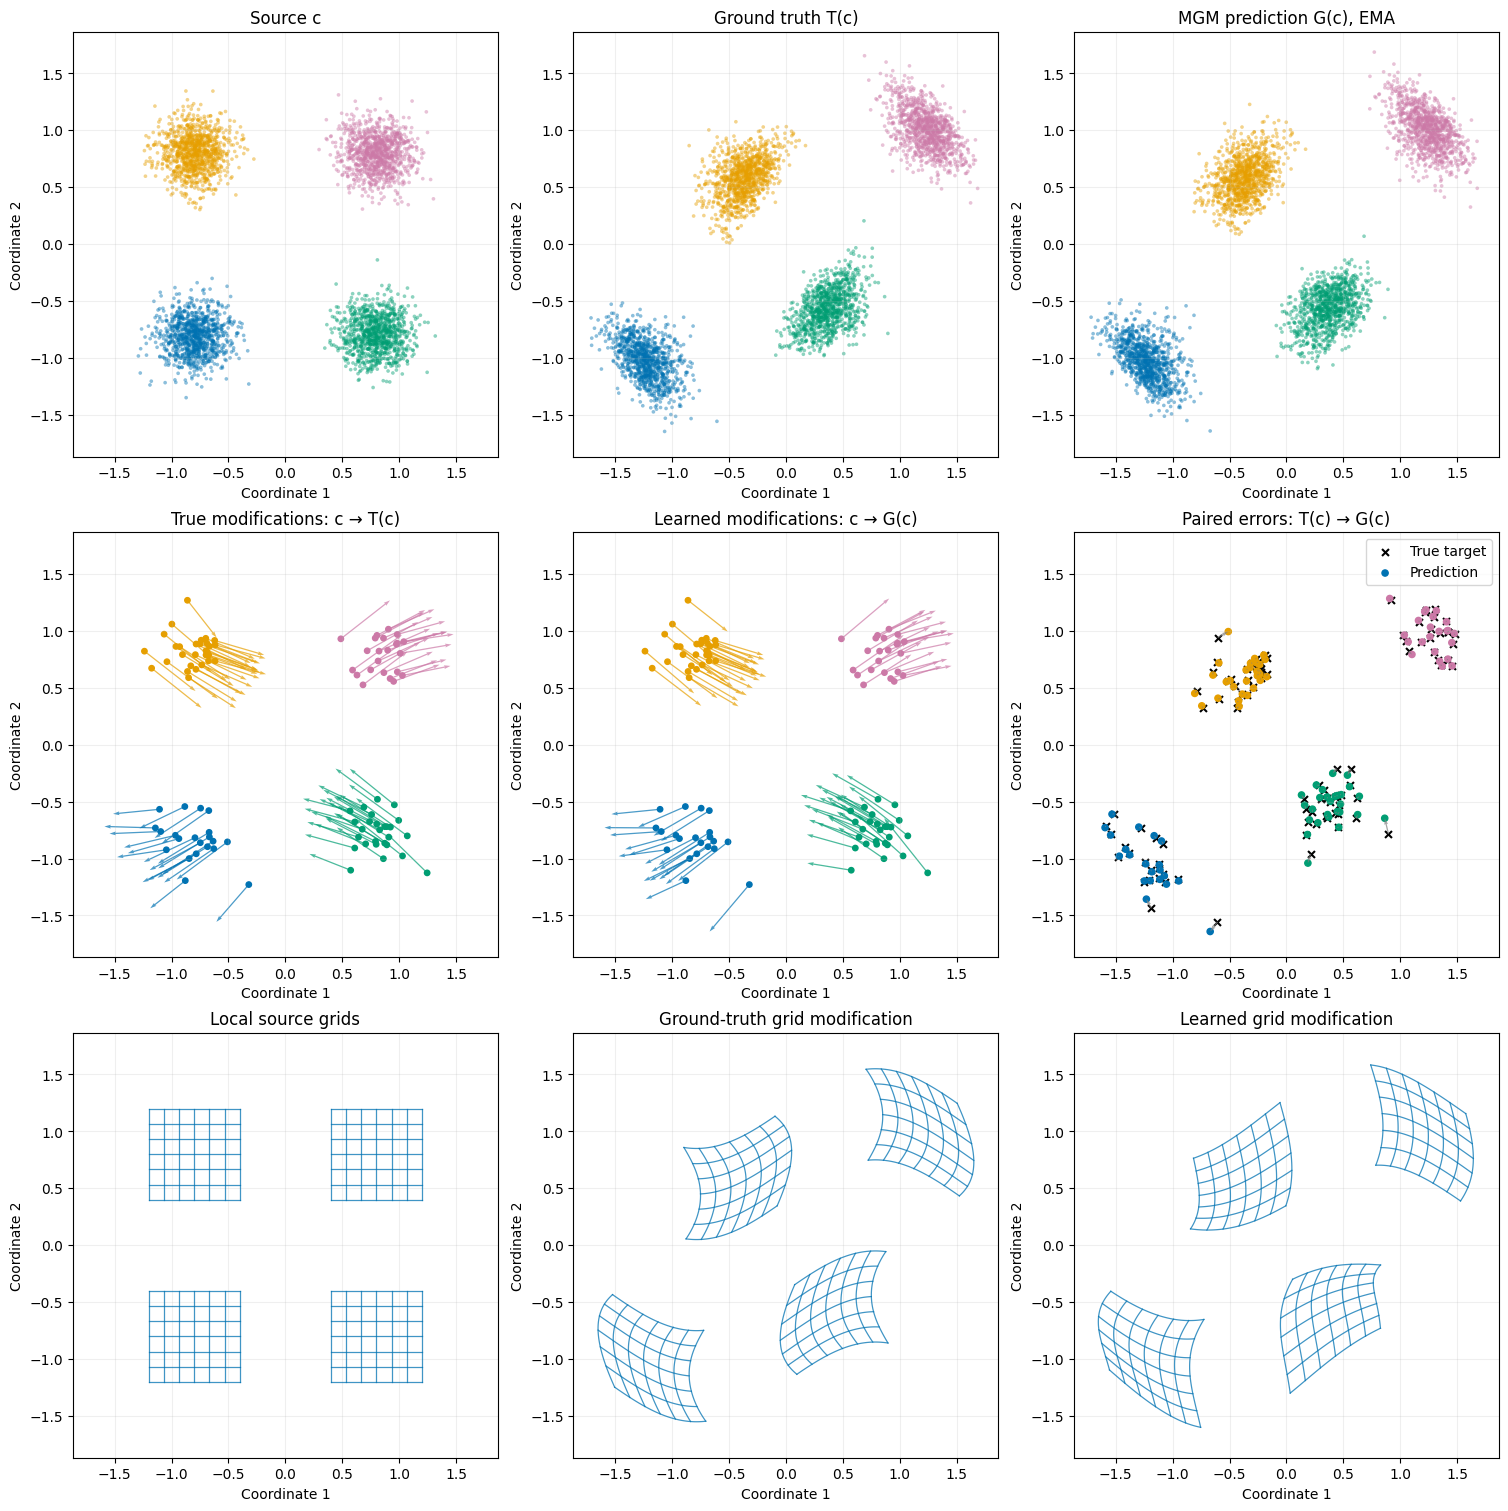

In [9]:
G_ema.eval()

with torch.no_grad():
    predicted = G_ema(test_c)
    initial_prediction = initial_G(test_c)

c_np = test_c.cpu().numpy()
y_np = test_y.cpu().numpy()
pred_np = predicted.cpu().numpy()
labels_np = test_labels.numpy()

palette = np.array([
    "#0072B2", "#E69F00", "#009E73", "#CC79A7"
])
colors = palette[labels_np]

plot_rng = np.random.default_rng(SEED)
selected = plot_rng.choice(
    len(c_np), size=min(100, len(c_np)), replace=False
)

all_points = np.concatenate([c_np, y_np, pred_np], axis=0)
plot_limit = np.abs(all_points).max() + 0.15


def format_ax(ax, title, limit=plot_limit):
    ax.set_title(title)
    ax.set_xlabel("Coordinate 1")
    ax.set_ylabel("Coordinate 2")
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)


# ------------------------------------------------------------
# Population and paired correspondence
# ------------------------------------------------------------
fig, axes = plt.subplots(
    3, 3, figsize=(15, 15), constrained_layout=True
)

for ax, points, title in zip(
    axes[0],
    [c_np, y_np, pred_np],
    ["Source c", "Ground truth T(c)", "MGM prediction G(c), EMA"],
):
    ax.scatter(
        points[:, 0], points[:, 1],
        c=colors, s=7, alpha=0.45, linewidths=0,
    )
    format_ax(ax, title)

cs = c_np[selected]
ys = y_np[selected]
ps = pred_np[selected]
selected_colors = colors[selected]

axes[1, 0].quiver(
    cs[:, 0], cs[:, 1],
    ys[:, 0] - cs[:, 0], ys[:, 1] - cs[:, 1],
    color=selected_colors,
    angles="xy", scale_units="xy", scale=1,
    width=0.003, alpha=0.7,
)
axes[1, 0].scatter(
    cs[:, 0], cs[:, 1], c=selected_colors, s=15
)
format_ax(axes[1, 0], "True modifications: c → T(c)")

axes[1, 1].quiver(
    cs[:, 0], cs[:, 1],
    ps[:, 0] - cs[:, 0], ps[:, 1] - cs[:, 1],
    color=selected_colors,
    angles="xy", scale_units="xy", scale=1,
    width=0.003, alpha=0.7,
)
axes[1, 1].scatter(
    cs[:, 0], cs[:, 1], c=selected_colors, s=15
)
format_ax(axes[1, 1], "Learned modifications: c → G(c)")

axes[1, 2].scatter(
    ys[:, 0], ys[:, 1],
    color="black", marker="x", s=25, label="True target",
)
axes[1, 2].scatter(
    ps[:, 0], ps[:, 1],
    c=selected_colors, s=20, label="Prediction",
)
axes[1, 2].quiver(
    ys[:, 0], ys[:, 1],
    ps[:, 0] - ys[:, 0], ps[:, 1] - ys[:, 1],
    color="gray",
    angles="xy", scale_units="xy", scale=1,
    width=0.003, alpha=0.7,
)
axes[1, 2].legend()
format_ax(axes[1, 2], "Paired errors: T(c) → G(c)")
# plt.show()

# ------------------------------------------------------------
# Training curves and held-out error distribution
# ------------------------------------------------------------
# steps = np.array([row["step"] for row in history])
# paired_mse = np.array([
#     row["paired_mse"] for row in history
# ])
# field_losses = np.array([
#     row["field_loss"] for row in history
# ])
# generator_losses = np.array([
#     row["generator_loss"] for row in history
# ])

# identity_distance = np.linalg.norm(c_np - y_np, axis=1)
# prediction_distance = np.linalg.norm(pred_np - y_np, axis=1)

# fig, axes = plt.subplots(
#     1, 3, figsize=(16, 4), constrained_layout=True
# )

# axes[0].semilogy(
#     steps, np.maximum(paired_mse, 1e-12),
#     label="EMA paired squared error",
# )
# axes[0].set_title("Held-out paired error")
# axes[0].set_xlabel("Generator updates")
# axes[0].set_ylabel("Mean squared Euclidean error")
# axes[0].grid(alpha=0.3)
# axes[0].legend()

# axes[1].plot(
#     steps, field_losses, label="Field regression loss"
# )
# axes[1].plot(
#     steps, generator_losses, label="Generator variational loss"
# )
# axes[1].axhline(0, color="black", linewidth=0.6)
# axes[1].set_title("MGM objectives — not directly comparable")
# axes[1].set_xlabel("Generator updates")
# axes[1].grid(alpha=0.3)
# axes[1].legend()

# axes[2].hist(
#     identity_distance, bins=40, alpha=0.5,
#     density=True, label="Identity initialization",
# )
# axes[2].hist(
#     prediction_distance, bins=40, alpha=0.5,
#     density=True, label="MGM EMA",
# )
# axes[2].set_title("Held-out Euclidean errors")
# axes[2].set_xlabel("Distance to paired target")
# axes[2].set_ylabel("Density")
# axes[2].legend()
# plt.show()
# ------------------------------------------------------------
# Third row: grid deformation
# ------------------------------------------------------------
for ax, lines, title in zip(
    axes[2],
    [grid_array, true_grid, learned_grid],
    [
        "Local source grids",
        "Ground-truth grid modification",
        "Learned grid modification",
    ],
):
    for line in lines:
        ax.plot(
            line[:, 0], line[:, 1],
            color="#0072B2", linewidth=0.9, alpha=0.75,
        )
    format_ax(ax, title)

# Save all nine plots as one image
fig.savefig(
    "toy2d_results_3x3.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Check how L1-regression will do the same thing

In [ ]:
import copy
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# Fresh generator: do NOT initialize from the MGM-trained G.
G_l1 = Generator(CFG["hidden"]).to(device)
G_l1_ema = copy.deepcopy(G_l1).eval()
G_l1_ema.requires_grad_(False)

opt_l1 = torch.optim.Adam(
    G_l1.parameters(),
    lr=CFG["lr_g"],
    betas=CFG["betas"],
)

L1_STEPS = CFG["steps"]       # 10,000 updates
L1_LOG_EVERY = CFG["log_every"]
l1_history = []

batch_iterator = iter(train_loader)

def next_l1_batch():
    global batch_iterator
    try:
        return next(batch_iterator)
    except StopIteration:
        batch_iterator = iter(train_loader)
        return next(batch_iterator)

G_l1.train()
pbar = tqdm(range(1, L1_STEPS + 1), desc="L1 regression")

for step in pbar:
    source, target = next_l1_batch()
    source = source.to(device=device, dtype=torch.float32)
    target = target.to(device=device, dtype=torch.float32)

    opt_l1.zero_grad(set_to_none=True)

    prediction = G_l1(source)
    loss_l1 = F.l1_loss(prediction, target)

    loss_l1.backward()

    if GRAD_CLIP is not None:
        torch.nn.utils.clip_grad_norm_(
            G_l1.parameters(), GRAD_CLIP
        )

    opt_l1.step()

    # EMA update once per generator update.
    with torch.no_grad():
        for p_ema, p in zip(
            G_l1_ema.parameters(), G_l1.parameters()
        ):
            p_ema.mul_(CFG["ema_decay"]).add_(
                p, alpha=1.0 - CFG["ema_decay"]
            )

    if step % L1_LOG_EVERY == 0 or step == 1 or step == L1_STEPS:
        metrics = evaluate(G_l1_ema)
        l1_history.append({
            "step": step,
            "train_l1": loss_l1.item(),
            **metrics,
        })

        print(
            f"L1 | step {step}/{L1_STEPS} | "
            f"train_L1={loss_l1.item():.5f} | "
            f"test_L1={F.l1_loss(G_l1_ema(test_c), test_y).item():.5f} | "
            f"paired_MSE={metrics['paired_mse']:.6f} | "
            f"inverse_MSE={metrics['inverse_mse']:.6f}"
        )

print("\nFinal L1 baseline:")
print("EMA:", evaluate(G_l1_ema))
print("Raw:", evaluate(G_l1))

L1 regression:   0%|          | 0/10000 [00:00<?, ?it/s]

L1 | step 1/10000 | train_L1=0.31802 | test_L1=0.32269 | paired_MSE=0.237693 | inverse_MSE=0.232878
L1 | step 100/10000 | train_L1=0.07095 | test_L1=0.32145 | paired_MSE=0.236112 | inverse_MSE=0.231612
L1 | step 200/10000 | train_L1=0.06545 | test_L1=0.31743 | paired_MSE=0.230733 | inverse_MSE=0.227309
L1 | step 300/10000 | train_L1=0.06705 | test_L1=0.31121 | paired_MSE=0.222361 | inverse_MSE=0.220560
L1 | step 400/10000 | train_L1=0.06765 | test_L1=0.30292 | paired_MSE=0.211305 | inverse_MSE=0.211538
L1 | step 500/10000 | train_L1=0.06715 | test_L1=0.29281 | paired_MSE=0.198087 | inverse_MSE=0.200577
L1 | step 600/10000 | train_L1=0.06237 | test_L1=0.28116 | paired_MSE=0.183313 | inverse_MSE=0.188083
L1 | step 700/10000 | train_L1=0.05889 | test_L1=0.26827 | paired_MSE=0.167532 | inverse_MSE=0.174435
L1 | step 800/10000 | train_L1=0.05610 | test_L1=0.25430 | paired_MSE=0.151138 | inverse_MSE=0.159895
L1 | step 900/10000 | train_L1=0.04520 | test_L1=0.23908 | paired_MSE=0.134111 | inv

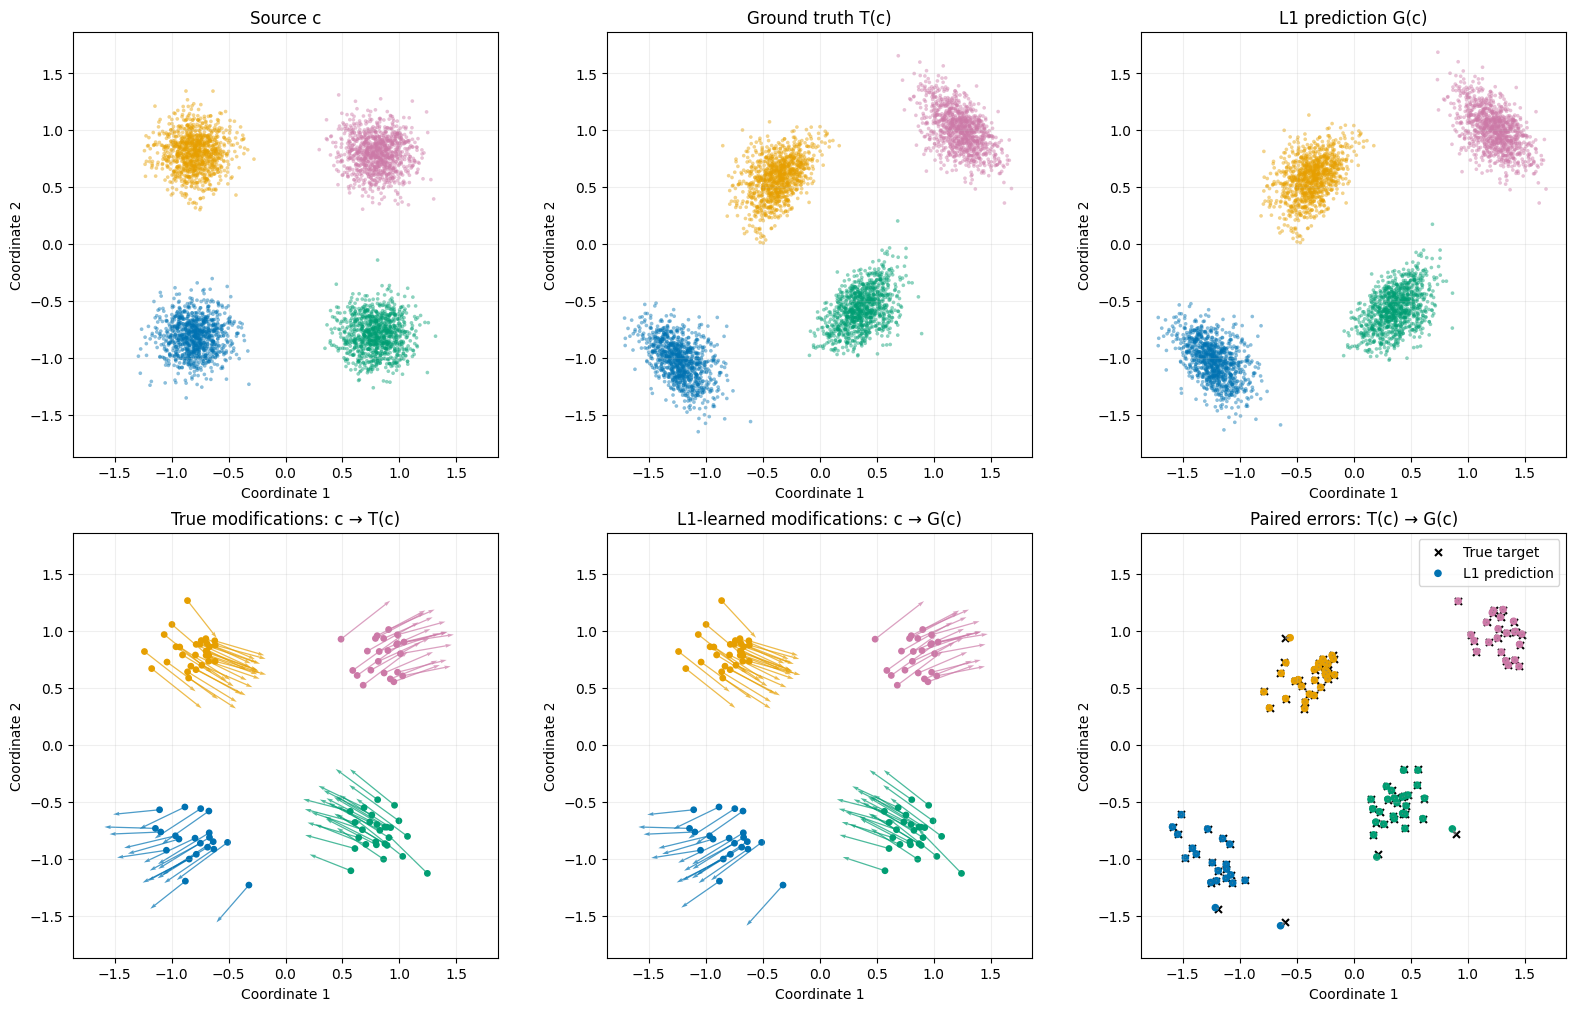

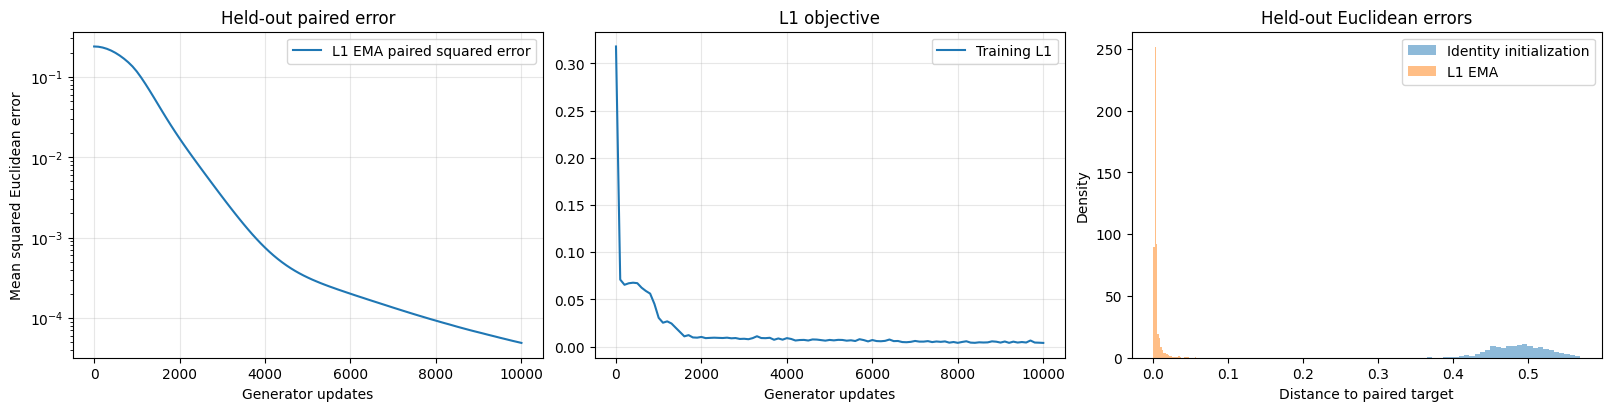

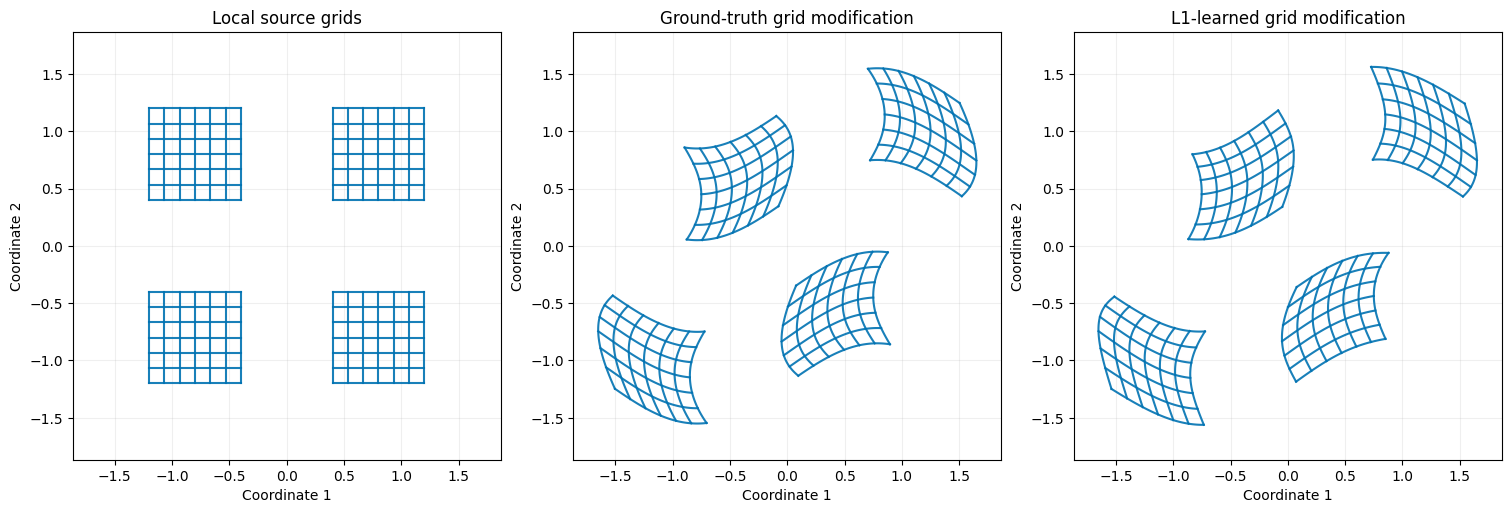

In [ ]:
G_l1_ema.eval()

with torch.no_grad():
    l1_predicted = G_l1_ema(test_c)

c_np = test_c.cpu().numpy()
y_np = test_y.cpu().numpy()
pred_np = l1_predicted.cpu().numpy()
labels_np = test_labels.numpy()

palette = np.array([
    "#0072B2", "#E69F00", "#009E73", "#CC79A7"
])
colors = palette[labels_np]

plot_rng = np.random.default_rng(SEED)
selected = plot_rng.choice(
    len(c_np), size=min(100, len(c_np)), replace=False
)

all_points = np.concatenate([c_np, y_np, pred_np], axis=0)
plot_limit = np.abs(all_points).max() + 0.15

def format_ax(ax, title, limit=plot_limit):
    ax.set_title(title)
    ax.set_xlabel("Coordinate 1")
    ax.set_ylabel("Coordinate 2")
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

# ------------------------------------------------------------
# Population and paired correspondence
# ------------------------------------------------------------
fig, axes = plt.subplots(
    2, 3, figsize=(16, 10), constrained_layout=True
)

for ax, points, title in zip(
    axes[0],
    [c_np, y_np, pred_np],
    ["Source c", "Ground truth T(c)", "L1 prediction G(c)"],
):
    ax.scatter(
        points[:, 0], points[:, 1],
        c=colors, s=7, alpha=0.45, linewidths=0,
    )
    format_ax(ax, title)

cs = c_np[selected]
ys = y_np[selected]
ps = pred_np[selected]
selected_colors = colors[selected]

axes[1, 0].quiver(
    cs[:, 0], cs[:, 1],
    ys[:, 0] - cs[:, 0], ys[:, 1] - cs[:, 1],
    color=selected_colors,
    angles="xy", scale_units="xy", scale=1,
    width=0.003, alpha=0.7,
)
axes[1, 0].scatter(cs[:, 0], cs[:, 1], c=selected_colors, s=15)
format_ax(axes[1, 0], "True modifications: c → T(c)")

axes[1, 1].quiver(
    cs[:, 0], cs[:, 1],
    ps[:, 0] - cs[:, 0], ps[:, 1] - cs[:, 1],
    color=selected_colors,
    angles="xy", scale_units="xy", scale=1,
    width=0.003, alpha=0.7,
)
axes[1, 1].scatter(cs[:, 0], cs[:, 1], c=selected_colors, s=15)
format_ax(axes[1, 1], "L1-learned modifications: c → G(c)")

axes[1, 2].scatter(
    ys[:, 0], ys[:, 1],
    color="black", marker="x", s=25, label="True target",
)
axes[1, 2].scatter(
    ps[:, 0], ps[:, 1],
    c=selected_colors, s=20, label="L1 prediction",
)
axes[1, 2].quiver(
    ys[:, 0], ys[:, 1],
    ps[:, 0] - ys[:, 0], ps[:, 1] - ys[:, 1],
    color="gray",
    angles="xy", scale_units="xy", scale=1,
    width=0.003, alpha=0.7,
)
axes[1, 2].legend()
format_ax(axes[1, 2], "Paired errors: T(c) → G(c)")

plt.show()

# ------------------------------------------------------------
# Training curve and held-out error distribution
# ------------------------------------------------------------
steps = np.array([row["step"] for row in l1_history])
paired_mse = np.array([row["paired_mse"] for row in l1_history])
train_l1 = np.array([row["train_l1"] for row in l1_history])

identity_distance = np.linalg.norm(c_np - y_np, axis=1)
l1_distance = np.linalg.norm(pred_np - y_np, axis=1)

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4), constrained_layout=True
)

axes[0].semilogy(
    steps, np.maximum(paired_mse, 1e-12),
    label="L1 EMA paired squared error",
)
axes[0].set_title("Held-out paired error")
axes[0].set_xlabel("Generator updates")
axes[0].set_ylabel("Mean squared Euclidean error")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(steps, train_l1, label="Training L1")
axes[1].set_title("L1 objective")
axes[1].set_xlabel("Generator updates")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[2].hist(
    identity_distance, bins=40, alpha=0.5,
    density=True, label="Identity initialization",
)
axes[2].hist(
    l1_distance, bins=40, alpha=0.5,
    density=True, label="L1 EMA",
)
axes[2].set_title("Held-out Euclidean errors")
axes[2].set_xlabel("Distance to paired target")
axes[2].set_ylabel("Density")
axes[2].legend()

plt.show()

# ------------------------------------------------------------
# Grid deformation — same grid coordinates as the MGM plot
# ------------------------------------------------------------
centers = [
    (-0.8, -0.8), (-0.8, 0.8),
    (0.8, -0.8), (0.8, 0.8),
]

GRID_RADIUS = 0.40
GRID_LINES = 7

grid_lines = []
for cx, cy in centers:
    horizontal = np.linspace(cx - GRID_RADIUS, cx + GRID_RADIUS, 120)
    vertical = np.linspace(cy - GRID_RADIUS, cy + GRID_RADIUS, 120)

    for offset in np.linspace(-GRID_RADIUS, GRID_RADIUS, GRID_LINES):
        grid_lines.append(np.column_stack([
            horizontal,
            np.full_like(horizontal, cy + offset),
        ]))
        grid_lines.append(np.column_stack([
            np.full_like(vertical, cx + offset),
            vertical,
        ]))

grid_array = np.stack(grid_lines)
grid_tensor = torch.tensor(
    grid_array, dtype=torch.float32, device=device
)

with torch.no_grad():
    true_grid = transform(grid_tensor).cpu().numpy()
    l1_grid = G_l1_ema(
        grid_tensor.reshape(-1, 2)
    ).reshape_as(grid_tensor).cpu().numpy()

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), constrained_layout=True
)

for ax, lines, title in zip(
    axes,
    [grid_array, true_grid, l1_grid],
    [
        "Local source grids",
        "Ground-truth grid modification",
        "L1-learned grid modification",
    ],
):
    for line in lines:
        ax.plot(
            line[:, 0], line[:, 1],
            color="#0072B2", linewidth=1.5, alpha=0.9,
        )
    format_ax(ax, title)

plt.show()